# קולות של אבו-יאיר

How the Arab sector voted for Likud, Shas and the rest, 2009–2026, and where Netanyahu's "Abu Yair" outreach (Jan–Mar 2021, before Knesset 24) falls.

**Arab-sector polling station**: >75% of valid votes went to Arab parties (incl. Hadash), the same rule as the project's Haredi definition.
Shares are of **registered voters**, so *not voted* (registered − valid) is a group of its own.

Data notes: Knesset 17 (2006) has registered voters = votes cast in the raw file, so abstention is unknowable and it is skipped;
`results_15.csv` and `results_16.csv` hold the same 1999 data, so 2003 is not available.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "kn25_26_flows" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from src.plot_utils import heb

plt.rcParams["font.family"] = "Arial"  # has Hebrew glyphs

# Arab party ballot letters per Knesset (Hadash included)
ARAB = {
    18: ["ו", "עם", "ד"], 19: ["ו", "עם", "ד"], 20: ["ודעם"], 21: ["ום", "דעם"],
    22: ["ודעם"], 23: ["ודעם"], 24: ["ודעם", "עם"], 25: ["ום", "עם", "ד"], 26: ["ודם", "עם", "ד"],
}
META = {"סמל ועדה", "ברזל", "שם ישוב", "סמל ישוב", "קלפי", "ריכוז", "שופט", "בזב", "מצביעים",
        "פסולים", "כשרים", "חיצוניות", "קלפי אחרת", "ת. עדכון"}
THRESHOLD = 0.75
dates = pd.read_csv(ROOT / "data/external/election_dates.csv", index_col=0, parse_dates=["election_date"])["election_date"]


def load(k):
    df = pd.read_csv(ROOT / f"data/raw/results_{k}.csv")
    df.columns = df.columns.str.strip()
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
    parties = [c for c in df.columns if c not in META]
    df = df[df["בזב"] > 0]  # drops double-envelope pseudo-stations
    assert set(ARAB[k]) <= set(parties), (k, set(ARAB[k]) - set(parties))
    return df, parties


rows, other_parties = [], {}
for k in ARAB:
    df, parties = load(k)
    arab = df[ARAB[k]].sum(axis=1)
    sec = df[arab > THRESHOLD * df["כשרים"]]
    g = pd.Series({
        "arab parties": sec[ARAB[k]].sum().sum(),
        "likud": sec["מחל"].sum(),
        "shas": sec["שס"].sum(),
    })
    g["other"] = sec["כשרים"].sum() - g.sum()
    g["not voted"] = (sec["בזב"] - sec["כשרים"]).clip(lower=0).sum()
    rows.append(g.rename(k))
    rest = sec[[p for p in parties if p not in ARAB[k] + ["מחל", "שס"]]].sum()
    other_parties[k] = rest.sort_values(ascending=False).head(5)
    print(f"Kn{k}: {len(sec):,} of {len(df):,} stations, {sec['בזב'].sum():,} registered")

votes = pd.DataFrame(rows)
votes.index.name = "knesset"
share = votes.div(votes.sum(axis=1), axis=0)

Kn18: 820 of 9,264 stations, 509,025 registered
Kn19: 814 of 9,881 stations, 514,638 registered
Kn20: 961 of 10,119 stations, 615,440 registered
Kn21: 808 of 10,460 stations, 549,332 registered
Kn22: 1,021 of 10,539 stations, 686,237 registered
Kn23: 1,192 of 10,631 stations, 800,677 registered
Kn24: 1,405 of 12,127 stations, 745,724 registered
Kn25: 1,465 of 11,707 stations, 845,948 registered
Kn26: 1,434 of 12,018 stations, 959,876 registered


## Votes and shares of registered voters

In [2]:
out = votes.astype(int).join((share * 100).round(2), rsuffix=" %")
out.insert(0, "date", dates[out.index].dt.strftime("%d/%m/%Y"))
out

,date,arab parties,likud,shas,other,not voted,arab parties %,likud %,shas %,other %,not voted %
knesset,,,,,,,,,,,
18,10/02/2009,252728,1693,2381,16389,235834,49.65,0.33,0.47,3.22,46.33
19,22/01/2013,261270,3808,4835,21180,223545,50.77,0.74,0.94,4.12,43.44
20,17/03/2015,365842,2629,2405,26783,217781,59.44,0.43,0.39,4.35,35.39
21,09/04/2019,232554,1757,2829,28170,284022,42.33,0.32,0.51,5.13,51.70
22,17/09/2019,373370,2829,3113,29404,277521,54.41,0.41,0.45,4.28,40.44
23,02/03/2020,493796,4057,2169,19519,281136,61.67,0.51,0.27,2.44,35.11
24,23/03/2021,297328,8188,1920,18386,419902,39.87,1.10,0.26,2.47,56.31
25,01/11/2022,421143,5439,1428,18388,399550,49.78,0.64,0.17,2.17,47.23
26,27/10/2026,727360,3293,580,27598,201045,75.78,0.34,0.06,2.88,20.94


Likud and Shas as a share of **valid** votes (the usual way to talk about it):

In [3]:
valid = votes.drop(columns="not voted")
(valid.div(valid.sum(axis=1), axis=0) * 100).round(2)[["likud", "shas", "other"]]

,likud,shas,other
knesset,,,
18,0.62,0.87,6.00
19,1.31,1.66,7.28
20,0.66,0.60,6.74
21,0.66,1.07,10.62
22,0.69,0.76,7.19
23,0.78,0.42,3.76
24,2.51,0.59,5.64
25,1.22,0.32,4.12
26,0.43,0.08,3.64


Largest parties inside *other* (right-wing ones show up here):

In [4]:
pd.DataFrame({k: s.astype(int).to_dict() for k, s in other_parties.items()}).fillna(0).astype(int).T.loc[:, lambda d: d.sum().nlargest(10).index]

,אמת,מרצ,פה,ל,כן,מרץ,דרך,כ,כי,ע
18,3868,3317,0,1003,3922,0,0,0,0,0
19,6269,0,922,0,2471,5127,0,0,0,0
20,9151,8759,0,1406,0,0,0,1902,0,2233
21,1777,13126,5453,0,0,0,0,2404,0,0
22,3978,7566,9461,1513,0,0,0,0,3556,0
23,6779,0,7281,2140,0,0,0,0,0,0
24,1421,8922,2914,0,0,0,0,0,0,0
25,1932,5890,3755,727,2115,0,0,0,0,0
26,14041,0,0,3405,0,0,4797,0,0,0


## Timeline

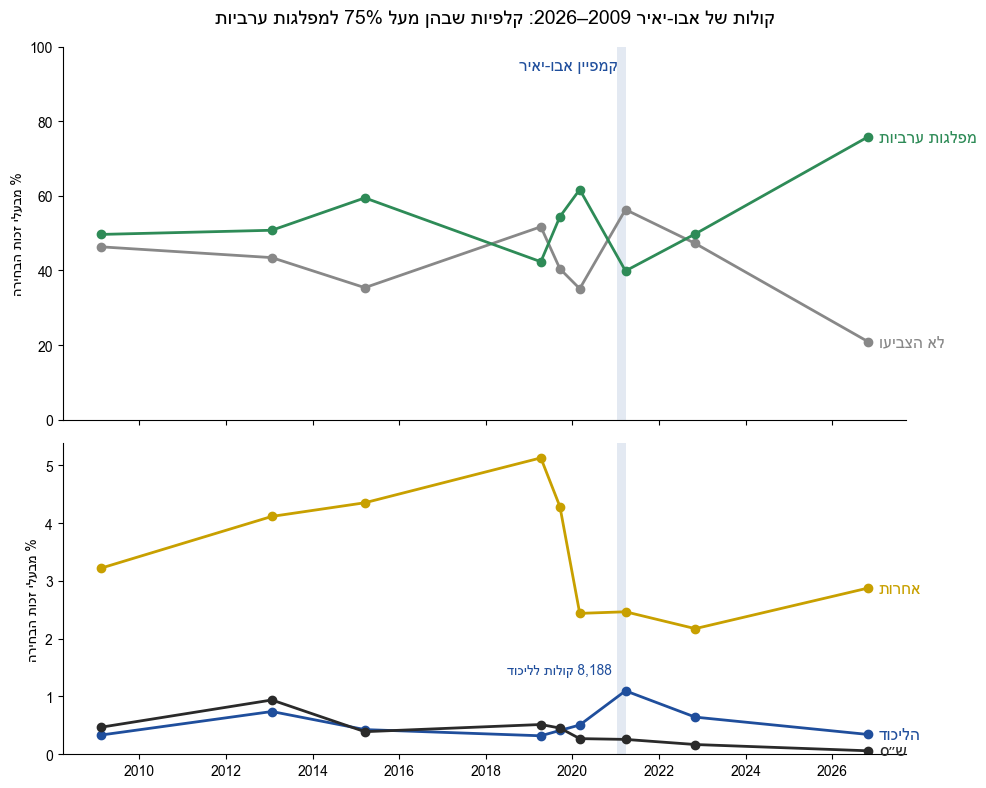

In [5]:
x = dates[share.index]
abu_yair = (pd.Timestamp("2021-01-13"), pd.Timestamp("2021-03-23"))  # Netanyahu's Nazareth visit -> Kn24 vote

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
for col, c in [("not voted", "#888888"), ("arab parties", "#2e8b57")]:
    a1.plot(x, share[col] * 100, "o-", color=c, lw=2)
    a1.annotate(heb({"not voted": "לא הצביעו", "arab parties": "מפלגות ערביות"}[col]), (x.iloc[-1], share[col].iloc[-1] * 100),
                xytext=(8, 0), textcoords="offset points", va="center", color=c, fontsize=12)
a1.set_ylabel(heb("% מבעלי זכות הבחירה"))
a1.set_ylim(0, 100)

for col, c, lab in [("likud", "#1f4e9c", "הליכוד"), ("shas", "#2a2a2a", "ש״ס"), ("other", "#c8a000", "אחרות")]:
    a2.plot(x, share[col] * 100, "o-", color=c, lw=2)
    a2.annotate(heb(lab), (x.iloc[-1], share[col].iloc[-1] * 100), xytext=(8, 0),
                textcoords="offset points", va="center", color=c, fontsize=12)
a2.set_ylabel(heb("% מבעלי זכות הבחירה"))
a2.set_ylim(0, None)
k24 = share.loc[24, "likud"] * 100
a2.annotate(heb(f"{votes.loc[24, 'likud']:,.0f} קולות לליכוד"), (x[24], k24), xytext=(-10, 12),
            textcoords="offset points", ha="right", color="#1f4e9c", fontsize=10)

for ax in (a1, a2):
    ax.axvspan(*abu_yair, color="#1f4e9c", alpha=0.12, lw=0)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
a1.text(abu_yair[0], 97, heb("קמפיין אבו-יאיר"), ha="right", va="top", color="#1f4e9c", fontsize=12)
a2.xaxis.set_major_locator(mdates.YearLocator(2))
a2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle(heb(f"קולות של אבו-יאיר 2009–2026: קלפיות שבהן מעל {THRESHOLD:.0%} למפלגות ערביות"), fontsize=14)
fig.tight_layout()
fig.savefig(ROOT / "data/processed/kn25_26_flows/abu_yair.png", dpi=150, bbox_inches="tight")

## Caveats
- The sector is re-defined every election, so a station where Likud did really well can drop below 75% Arab-party share and leave the sample. Likud's peak is therefore a lower bound.
- Druze and Bedouin-north villages that mostly vote for Zionist parties are excluded by construction.